# 07 – Phân tích lỗi

In [1]:
# Colab: Runtime > Change runtime type > GPU (T4)
from google.colab import drive
drive.mount('/content/drive')
import sys
PROJECT = "/content/drive/MyDrive/FER2013_PyTorch"
sys.path.insert(0, PROJECT)
from common import *
print("Device:", DEV, "| torch", torch.__version__)

Mounted at /content/drive
Device: cpu | torch 2.14.1+cpu


In [2]:
from data import *
from models import *
from train_lib import evaluate
rows = [json.loads(p.read_text()) for p in RUNS_DIR.glob('*/results.json')]
BEST = max(rows, key=lambda r: r['val_acc'])['exp_name']   # hoặc gán tay
ck = torch.load(RUNS_DIR/BEST/'best.pt', map_location=DEV); cfg = ck['cfg']
model = build_model(cfg['model'], cfg['img_size'], cfg['bn'], cfg['conv_drop'], cfg['fc_drop'], False).to(DEV)
model.load_state_dict(ck['state_dict'])
loaders, _, _ = make_loaders(128, 'none', cfg['img_size'], 2)
_, ta, pred, tgt = evaluate(model, loaders['test'], nn.CrossEntropyLoss())
print(BEST, f'| test acc {ta:.4f}')
cm = confusion_matrix(tgt, pred, labels=range(7))
print({c: round(float(r),3) for c, r in zip(CLASSES, cm.diagonal()/cm.sum(1))})

A_vgg16_ft | test acc 0.7058
{'Angry': 0.621, 'Disgust': 0.673, 'Fear': 0.53, 'Happy': 0.885, 'Sad': 0.582, 'Surprise': 0.805, 'Neutral': 0.722}


## 7.1 Các cặp lớp nhầm nhiều nhất

In [3]:
pairs = [(CLASSES[i], CLASSES[j], int(cm[i,j])) for i in range(7) for j in range(7) if i != j]
for t, p, n in sorted(pairs, key=lambda z: -z[2])[:8]: print(f'True {t:9s} -> Pred {p:9s}: {n} ảnh')

True Sad       -> Pred Neutral  : 111 ảnh
True Fear      -> Pred Sad      : 104 ảnh
True Neutral   -> Pred Sad      : 90 ảnh
True Angry     -> Pred Sad      : 71 ảnh
True Sad       -> Pred Fear     : 60 ảnh
True Fear      -> Pred Angry    : 55 ảnh
True Sad       -> Pred Angry    : 51 ảnh
True Angry     -> Pred Fear     : 46 ảnh


## 7.2 Ảnh dự đoán sai

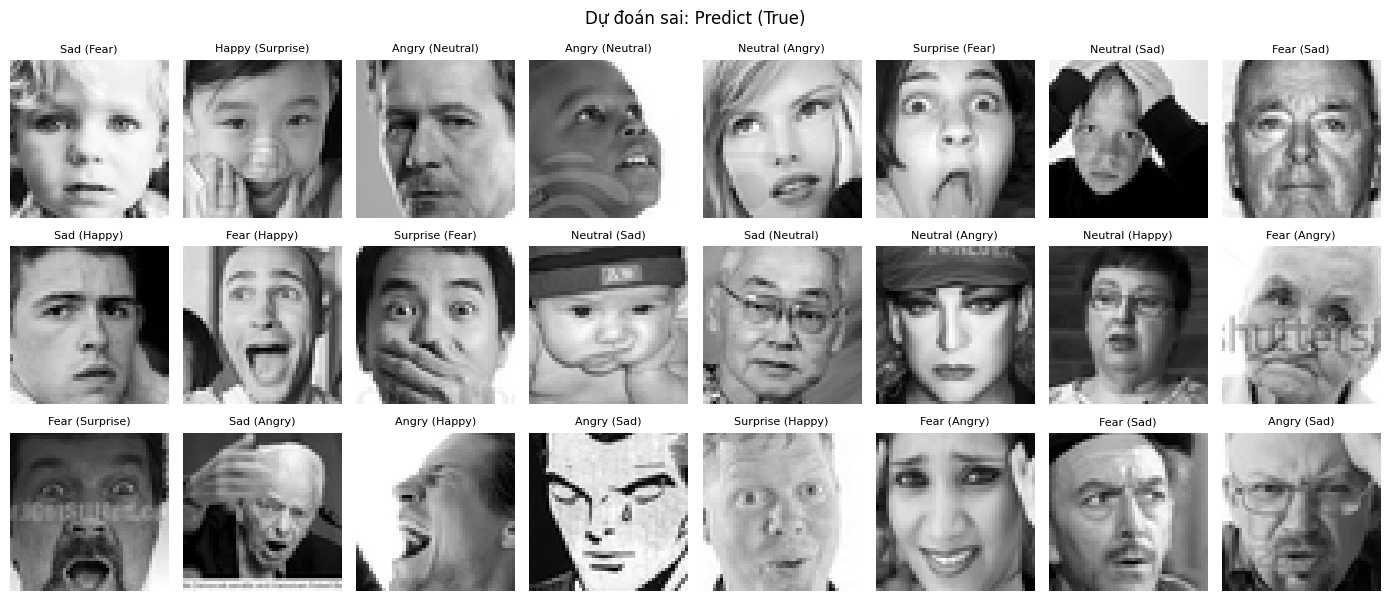

In [4]:
wrong = np.where(pred != tgt)[0]; pick = np.random.RandomState(0).choice(wrong, 24, replace=False)
fig, axs = plt.subplots(3, 8, figsize=(14,6.2))
for a, i in zip(axs.ravel(), pick):
    a.imshow(get_data()['test'][0][i], cmap='gray'); a.set_title(f'{CLASSES[pred[i]]} ({CLASSES[tgt[i]]})', fontsize=8); a.axis('off')
fig.suptitle('Dự đoán sai: Predict (True)'); fig.tight_layout(); plt.show()

## 7.3 Ảnh dự đoán đúng

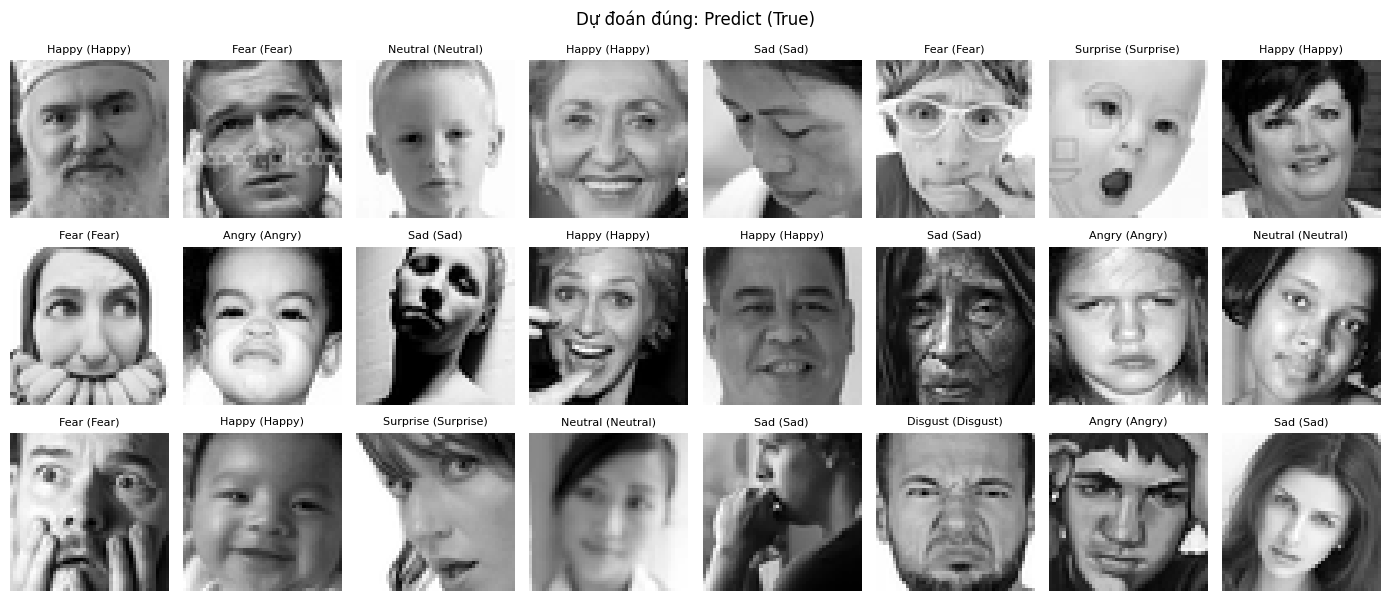

In [5]:
right = np.where(pred == tgt)[0]; pick = np.random.RandomState(1).choice(right, 24, replace=False)
fig, axs = plt.subplots(3, 8, figsize=(14,6.2))
for a, i in zip(axs.ravel(), pick):
    a.imshow(get_data()['test'][0][i], cmap='gray'); a.set_title(f'{CLASSES[pred[i]]} ({CLASSES[tgt[i]]})', fontsize=8); a.axis('off')
fig.suptitle('Dự đoán đúng: Predict (True)'); fig.tight_layout(); plt.show()